<a href="https://colab.research.google.com/github/USERNAME/Grokking-Deep-Learning/blob/main/10_convolutional-neural-networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 10: Neural Learning About Edges and Corners
## Introduction to convolutional neural networks

**Companion notebook for *Grokking Deep Learning* (Andrew W. Trask, Manning)**

This notebook explains why reusing weights helps, shows what a convolutional kernel does on real digits, reproduces the book's NumPy implementation, and trains it on MNIST. The training cells take a few minutes in total (about **5 minutes** on a typical machine).

---
## Reusing weights in multiple places

**If you need to detect the same feature in multiple places, use the same weights.**

The greatest challenge in neural networks is **overfitting**, and it is largely about the **ratio between the number of weights and the number of datapoints** available to learn them. With many parameters and few examples, the network can memorize ("ah, image 363 again, that was a 2") instead of learning abstractions ("a swoop on top, a swirl bottom left, a tail on the right: a 2").

Chapter 8 fought this with regularization, but there is a better weapon whenever it applies: **structure**. Structure means deliberately *reusing* the same weights for several purposes because the same pattern must be detected in several places. Reuse lowers the weight-to-data ratio, so the model stays equally expressive but is much more robust to overfitting, and it also becomes smaller. The most famous such structure is the **convolution**; used as a layer, it is a **convolutional layer**.

### Loading MNIST
The book calls `keras.datasets.mnist` (preinstalled on Colab). The cell below does exactly that, and **falls back to downloading the same MNIST data from a public GitHub mirror** if Keras isn't available, so the notebook also runs outside Colab. As in the book, we train on only the **first 1,000 images** and test on the standard **10,000 test images**. I also keep images 1,000–1,999 as a *validation set* (used for early stopping later).

In [1]:
import sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt

def load_mnist():
    try:
        from keras.datasets import mnist                      # what the book uses
        (x_train, y_train), (x_test, y_test) = mnist.load_data()
        x_train = x_train.reshape(len(x_train), 784) / 255
        x_test  = x_test.reshape(len(x_test), 784) / 255
    except Exception:                                         # fallback: same dataset from a GitHub mirror
        import gzip, pickle, os, urllib.request
        url = "https://raw.githubusercontent.com/mnielsen/neural-networks-and-deep-learning/master/data/mnist.pkl.gz"
        if not os.path.exists("mnist.pkl.gz"):
            urllib.request.urlretrieve(url, "mnist.pkl.gz")
        with gzip.open("mnist.pkl.gz", "rb") as f, warnings.catch_warnings():
            warnings.simplefilter("ignore")
            train, valid, test = pickle.load(f, encoding="latin1")
        x_train, y_train = train[0].astype("float64"), train[1]
        x_test,  y_test  = test[0].astype("float64"),  test[1]

    def one_hot(y):
        out = np.zeros((len(y), 10))
        out[np.arange(len(y)), y] = 1
        return out

    images,      labels      = x_train[0:1000],    one_hot(y_train[0:1000])
    val_images,  val_labels  = x_train[1000:2000], one_hot(y_train[1000:2000])
    test_images, test_labels = x_test,             one_hot(y_test)
    return images, labels, val_images, val_labels, test_images, test_labels

images, labels, val_images, val_labels, test_images, test_labels = load_mnist()
print("train :", images.shape, labels.shape)
print("val   :", val_images.shape)
print("test  :", test_images.shape, test_labels.shape)
print("first labels:", labels[:10].argmax(axis=1))

train : (1000, 784) (1000, 10)
val   : (1000, 784)
test  : (10000, 784) (10000, 10)
first labels: [5 0 4 1 9 2 1 3 1 4]


---
## The convolutional layer

Instead of one big dense layer connecting every input to every output, use **many very small linear layers, reused at every position**. Each tiny layer (usually fewer than ~25 inputs and a single output) is called a **convolutional kernel**.

A 3 × 3 kernel:
1. predicts at its current location (a weighted sum of the 9 pixels under it),
2. moves one pixel to the right and predicts again,
3. ... until it reaches the end of the row, then moves down one pixel and repeats,

producing a grid of predictions (a smaller image) that becomes the input of the next layer. A convolutional layer usually has **many kernels**, each learning to detect a different pattern, and each is searched for *everywhere* in the image. Because the same small set of weights is trained on many positions, it effectively sees far more training data, which is exactly what reduces overfitting.

**My demo: three hand-made kernels on a real digit.** The kernels below respond to horizontal lines, vertical lines, and diagonals (`/`). A trained network *learns* such kernels itself; here we write them by hand to see the mechanics.

loops == vectorized: True


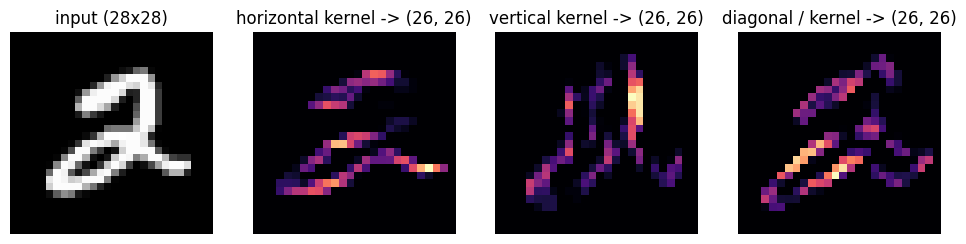

In [2]:
from numpy.lib.stride_tricks import sliding_window_view as swv

img = images[labels.argmax(1) == 2][0].reshape(28, 28)      # the first '2' in the training set

kernels_demo = {
    "horizontal": np.array([[-1, -1, -1], [ 2,  2,  2], [-1, -1, -1]]),
    "vertical"  : np.array([[-1,  2, -1], [-1,  2, -1], [-1,  2, -1]]),
    "diagonal /": np.array([[-1, -1,  2], [-1,  2, -1], [ 2, -1, -1]]),
}

def convolve(image, kernel):
    windows = swv(image, (3, 3))                 # shape (26, 26, 3, 3): every 3x3 patch
    return (windows * kernel).sum(axis=(2, 3))   # one weighted sum per patch

# the same thing with explicit loops, to see the "slide the kernel" mechanics
def convolve_loops(image, kernel):
    out = np.zeros((26, 26))
    for r in range(26):
        for col in range(26):
            out[r, col] = np.sum(image[r:r+3, col:col+3] * kernel)
    return out

k = kernels_demo["horizontal"]
print("loops == vectorized:", np.allclose(convolve_loops(img, k), convolve(img, k)))

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("input (28x28)")
for ax, (name, kern) in zip(axes[1:], kernels_demo.items()):
    fmap = np.maximum(convolve(img, kern), 0)    # keep only positive responses
    ax.imshow(fmap, cmap="magma"); ax.set_title(f"{name} kernel -> {fmap.shape}")
for ax in axes: ax.axis("off")
plt.show()

Each kernel lights up exactly where *its* pattern appears: the horizontal one on the base and top of the 2, the vertical one on near-vertical strokes. The output is a **smaller image** (26 × 26 for a 3 × 3 kernel on a 28 × 28 input), one value per position.

**Combining the kernels' outputs.** In the book's figure, four kernels look at the same 8 × 8 image of a 2 and produce four 6 × 6 prediction maps. These can be combined element-wise by **sum pooling**, **mean pooling**, or **max pooling** (take the largest of the kernels' outputs at each position); max is the most popular. Shown on our three maps:

In [3]:
maps = np.stack([np.maximum(convolve(img, kern), 0) for kern in kernels_demo.values()])   # (3, 26, 26)
print("stacked kernel outputs:", maps.shape)
for name, fn in [("sum", np.sum), ("mean", np.mean), ("max", np.max)]:
    print(f"{name:4s} pooling over kernels -> {fn(maps, axis=0).shape}")

stacked kernel outputs: (3, 26, 26)
sum  pooling over kernels -> (26, 26)
mean pooling over kernels -> (26, 26)
max  pooling over kernels -> (26, 26)


*(The book's NumPy implementation below does **not** pool: it feeds every kernel's output at every position straight into the next layer.)*

**Why this cuts overfitting:** compare the number of weights in the first layer.

In [4]:
positions = 25 * 25            # positions a 3x3 kernel visits in the book's implementation
n_kernels = 16
hidden = positions * n_kernels

dense_first_layer = 784 * hidden
conv_first_layer  = 3 * 3 * n_kernels
print(f"hidden units in layer_1                 : {hidden:,}")
print(f"dense first layer weights (784 x {hidden:,}): {dense_first_layer:,}")
print(f"convolutional first layer weights       : {conv_first_layer:,}")
print(f"-> {dense_first_layer // conv_first_layer:,} times fewer weights, yet each kernel is trained {positions} times per image")

hidden units in layer_1                 : 10,000
dense first layer weights (784 x 10,000): 7,840,000
convolutional first layer weights       : 144
-> 54,444 times fewer weights, yet each kernel is trained 625 times per image


---
## A simple implementation in NumPy

Think of a kernel as a **mini linear layer**. The trick that makes the code simple *and* fast:

1. Cut out **every 3 × 3 patch** of every image in the batch.
2. Treat each patch as its own tiny "image" (a row of 9 numbers). A batch of 128 images × 625 patches becomes a batch of 80,000 small inputs.
3. Run them all through **one ordinary linear layer** with `num_kernels` outputs: `flattened_input.dot(kernels)`. This is the same as running `num_kernels` kernels at every position.
4. Reshape back to `(batch, positions × kernels)` and carry on as usual.

First, the book's helper that selects the same sub-region for the whole batch (the book's printed version has a small typo, `subsection` vs `section`, fixed here):

In [5]:
def get_image_section(layer, row_from, row_to, col_from, col_to):
    section = layer[:, row_from:row_to, col_from:col_to]
    return section.reshape(-1, 1, row_to - row_from, col_to - col_from)

kernel_rows, kernel_cols, num_kernels = 3, 3, 16

def expand_book(layer_0):
    # the book's loop: collect every kernel-sized section of every image
    sects = list()
    for row_start in range(layer_0.shape[1] - kernel_rows):
        for col_start in range(layer_0.shape[2] - kernel_cols):
            sect = get_image_section(layer_0, row_start, row_start + kernel_rows,
                                     col_start, col_start + kernel_cols)
            sects.append(sect)
    expanded_input = np.concatenate(sects, axis=1)
    es = expanded_input.shape
    flattened_input = expanded_input.reshape(es[0] * es[1], -1)
    return flattened_input, es

batch = images[0:8].reshape(8, 28, 28)
flattened_input, es = expand_book(batch)
print("expanded shape        :", es, " (batch, positions, 3, 3)")
print("flattened_input shape :", flattened_input.shape, " (batch*positions, 9)")

kernels = 0.02 * np.random.random((kernel_rows * kernel_cols, num_kernels)) - 0.01
kernel_output = flattened_input.dot(kernels)
print("kernel_output shape   :", kernel_output.shape, " (batch*positions, num_kernels)")
print("layer_1 input shape   :", kernel_output.reshape(es[0], -1).shape, " (batch, positions*num_kernels)")

expanded shape        : (8, 625, 3, 3)  (batch, positions, 3, 3)
flattened_input shape : (5000, 9)  (batch*positions, 9)
kernel_output shape   : (5000, 16)  (batch*positions, num_kernels)
layer_1 input shape   : (8, 10000)  (batch, positions*num_kernels)


**Speed-up (my addition).** The Python double loop makes every training step slow (≈ 2 s per iteration). NumPy's `sliding_window_view` produces exactly the same patches in one call, so I use it for training and **prove it is identical** to the book's loop:

*(Note: the book loops over `range(28 - 3)` = 25 positions per axis, not 26, so the last row and column of patches is skipped. That's why `hidden_size = 25 × 25 × 16 = 10,000`. I keep the book's choice.)*

In [6]:
def expand(layer_0):
    windows = swv(layer_0, (3, 3), axis=(1, 2))[:, :25, :25]      # (batch, 25, 25, 3, 3)
    return windows.reshape(-1, 9), (layer_0.shape[0], 625, 3, 3)

fast, es_fast = expand(batch)
print("identical to the book's loop:", np.array_equal(fast, flattened_input), "| same shape info:", es_fast == es)

identical to the book's loop: True | same shape info: True


Now the book's training code. Differences from the listing are only (a) the faster `expand`, (b) the test set is evaluated in chunks every 10 iterations instead of image by image every iteration (identical numbers, much faster), and (c) a `kernel_sign` argument whose purpose is explained in the next section (`-1` = exactly the book's `kernels -= ...`).

In [7]:
def tanh(x): return np.tanh(x)
def tanh2deriv(output): return 1 - (output ** 2)
def softmax(x):
    temp = np.exp(x)
    return temp / np.sum(temp, axis=1, keepdims=True)

def cnn_predict(kernels, weights_1_2, X, chunk=500):
    preds = []
    for s in range(0, len(X), chunk):                           # chunks keep memory small
        flat, es = expand(X[s:s+chunk].reshape(-1, 28, 28))
        layer_1 = tanh(flat.dot(kernels).reshape(es[0], -1))
        preds.append(layer_1.dot(weights_1_2))
    return np.concatenate(preds)

def train_cnn(iterations=300, kernel_sign=-1, log_every=10, verbose=True):
    np.random.seed(1)
    alpha = 2
    pixels_per_image, num_labels = (784, 10)
    batch_size = 128
    input_rows, input_cols = 28, 28
    hidden_size = ((input_rows - kernel_rows) * (input_cols - kernel_cols)) * num_kernels

    kernels = 0.02 * np.random.random((kernel_rows * kernel_cols, num_kernels)) - 0.01
    weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1

    log = {"it": [], "train_acc_book": [], "train_acc": [], "test_acc": []}
    for j in range(iterations):
        correct_cnt = 0
        for i in range(int(len(images) / batch_size)):
            batch_start, batch_end = ((i * batch_size), ((i + 1) * batch_size))
            layer_0 = images[batch_start:batch_end].reshape(-1, 28, 28)

            flattened_input, es = expand(layer_0)
            kernel_output = flattened_input.dot(kernels)
            layer_1 = tanh(kernel_output.reshape(es[0], -1))
            dropout_mask = np.random.randint(2, size=layer_1.shape)
            layer_1 *= dropout_mask * 2
            layer_2 = softmax(np.dot(layer_1, weights_1_2))

            correct_cnt += int(np.sum(layer_2.argmax(axis=1) == labels[batch_start:batch_end].argmax(axis=1)))

            layer_2_delta = (labels[batch_start:batch_end] - layer_2) / (batch_size * layer_2.shape[0])
            layer_1_delta = layer_2_delta.dot(weights_1_2.T) * tanh2deriv(layer_1)
            layer_1_delta *= dropout_mask

            weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
            l1d_reshape = layer_1_delta.reshape(kernel_output.shape)
            k_update = flattened_input.T.dot(l1d_reshape)
            kernels += kernel_sign * alpha * k_update           # kernel_sign=-1  ->  kernels -= alpha * k_update  (the book)

        if j % log_every == 0 or j == iterations - 1:
            test_acc = np.mean(cnn_predict(kernels, weights_1_2, test_images).argmax(1) == test_labels.argmax(1))
            n_seen = int(len(images) / batch_size) * batch_size
            log["it"].append(j); log["test_acc"].append(test_acc)
            log["train_acc_book"].append(correct_cnt / len(images)); log["train_acc"].append(correct_cnt / n_seen)
            if verbose:
                print(f"I:{j:3d} Test-Acc:{test_acc:.4f} Train-Acc (book, /1000):{correct_cnt/len(images):.3f}  (/{n_seen} seen: {correct_cnt/n_seen:.3f})")
    return kernels, weights_1_2, log

t0 = time.time()
kernels_book, w12_book, log_book = train_cnn(iterations=300, kernel_sign=-1)
print(f"\ntraining time: {time.time()-t0:.0f} s")

I:  0 Test-Acc:0.0288 Train-Acc (book, /1000):0.055  (/896 seen: 0.061)


I: 10 Test-Acc:0.3519 Train-Acc (book, /1000):0.180  (/896 seen: 0.201)


I: 20 Test-Acc:0.0134 Train-Acc (book, /1000):0.021  (/896 seen: 0.023)


I: 30 Test-Acc:0.6595 Train-Acc (book, /1000):0.426  (/896 seen: 0.475)


I: 40 Test-Acc:0.7341 Train-Acc (book, /1000):0.540  (/896 seen: 0.603)


...

I:260 Test-Acc:0.8800 Train-Acc (book, /1000):0.804  (/896 seen: 0.897)


I:270 Test-Acc:0.8782 Train-Acc (book, /1000):0.813  (/896 seen: 0.907)


I:280 Test-Acc:0.8802 Train-Acc (book, /1000):0.815  (/896 seen: 0.910)


I:290 Test-Acc:0.8780 Train-Acc (book, /1000):0.817  (/896 seen: 0.912)


I:299 Test-Acc:0.8775 Train-Acc (book, /1000):0.815  (/896 seen: 0.910)

training time: 129 s


**Reading the output.**
- The book's `Train-Acc` divides by 1,000, but with `batch_size = 128` only **7 × 128 = 896** images are used per iteration, so it slightly understates the real training accuracy; I print both.
- Test accuracy starts *very* low (even below chance, and it wobbles for the first ~50 iterations) and then climbs to roughly **88%**: slightly better than the tanh + softmax network of Chapter 9 (≈ 87.0% in my run), and essentially the book's own result (87.7%). The book says "a few percentage points", but its own printed numbers (87.7% vs. 87%) differ by well under one point.

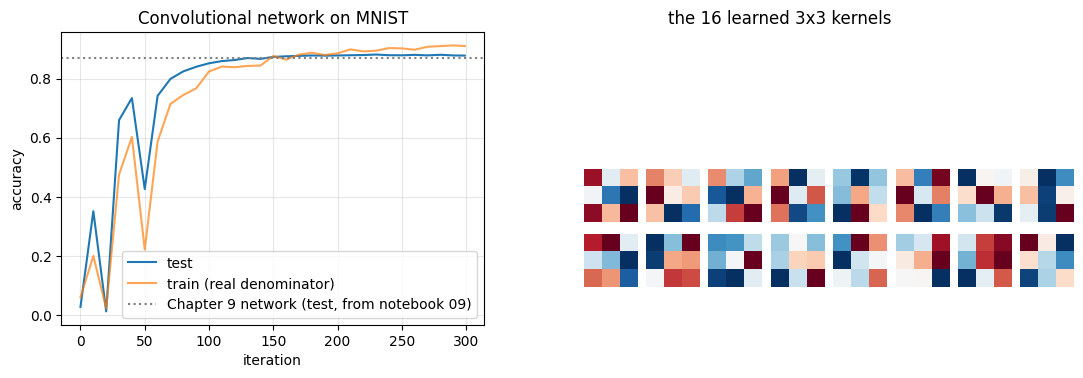

final test accuracy: 0.8775  (book reports 0.8774)


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(log_book["it"], log_book["test_acc"], label="test")
ax[0].plot(log_book["it"], log_book["train_acc"], label="train (real denominator)", alpha=.7)
ax[0].axhline(0.8705, color="gray", ls=":", label="Chapter 9 network (test, from notebook 09)")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("accuracy"); ax[0].set_title("Convolutional network on MNIST"); ax[0].legend(); ax[0].grid(alpha=.3)

for k in range(16):
    a = fig.add_axes([0.56 + (k % 8) * 0.052, 0.38 - (k // 8) * 0.17, 0.045, 0.14])
    a.imshow(kernels_book[:, k].reshape(3, 3), cmap="RdBu"); a.axis("off")
ax[1].axis("off"); ax[1].set_title("the 16 learned 3x3 kernels")
plt.show()
print(f"final test accuracy: {log_book['test_acc'][-1]:.4f}  (book reports 0.8774)")

The second panel shows the 16 learned kernels. Each is just 9 weights, trained on every position of every image.

---
## A small discrepancy in the book's listing (worth knowing)

While reproducing this, one line looked inconsistent. In Chapters 8 and 9 the delta is defined as **`labels − layer_2`** (target minus prediction), and weights are therefore updated with **`+=`**:

```python
layer_2_delta = (labels[...] - layer_2) / ...
weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
```

But in the Chapter 10 listing the kernels are updated with **`kernels -= alpha * k_update`**, the sign used back in Chapter 6, where the delta was `prediction − target`. With *this* chapter's delta convention the consistent update is **`+=`**. The signs for `weights_1_2` and `kernels` therefore disagree.

I tested both. The book's version (`kernel_sign=-1`) reproduces the book's printed log, including its odd start with a test accuracy of only ≈ 3% (**below** the 10% you get by guessing), which is a symptom of the kernels initially moving the wrong way. The consistent version (`kernel_sign=+1`) learns from the first iterations. (To keep the notebook quick I only run 100 iterations here.)

training time: 44 s


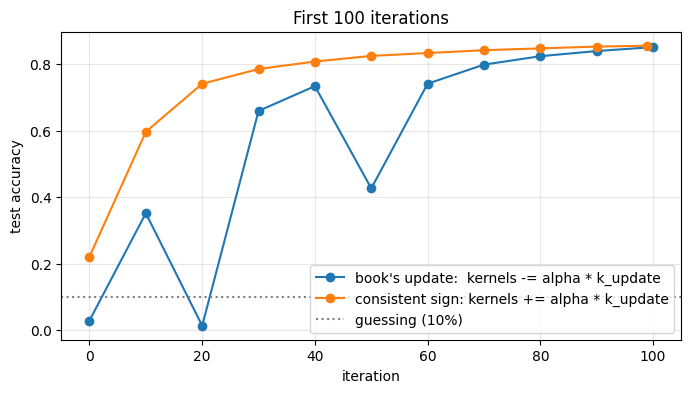

I:  0  book sign: 0.0288   consistent sign: 0.2209
I: 10  book sign: 0.3519   consistent sign: 0.5967
I: 50  book sign: 0.4266   consistent sign: 0.8251
I: 99  book sign: 0.8515   consistent sign: 0.8557


In [9]:
t0 = time.time()
kernels_fix, w12_fix, log_fix = train_cnn(iterations=100, kernel_sign=+1, log_every=10, verbose=False)
print(f"training time: {time.time()-t0:.0f} s")

n = len(log_fix["it"])
plt.figure(figsize=(8, 4))
plt.plot(log_book["it"][:n], log_book["test_acc"][:n], "o-", label="book's update:  kernels -= alpha * k_update")
plt.plot(log_fix["it"],      log_fix["test_acc"],      "o-", label="consistent sign: kernels += alpha * k_update")
plt.axhline(0.1, color="gray", ls=":", label="guessing (10%)")
plt.xlabel("iteration"); plt.ylabel("test accuracy"); plt.title("First 100 iterations"); plt.legend(); plt.grid(alpha=.3); plt.show()

for it, a, b in zip(log_fix["it"], log_book["test_acc"][:n], log_fix["test_acc"]):
    if it in (0, 10, 50, 99): print(f"I:{it:3d}  book sign: {a:.4f}   consistent sign: {b:.4f}")

**Take-away.** With the consistent sign the network starts learning at once; with the book's sign it first anti-learns and then recovers, and both end up in the same region (about 85% after 100 iterations). Over the full 300 iterations the book's version finished at 0.8775 (above), while a separate 300-iteration run I made of the consistent version was at about 0.87 (0.8695 at iteration 275), a gap too small to over-interpret from a single random seed. I have **not** investigated *why* the flipped-sign version still ends up as good. The goal here is only to flag the inconsistency honestly; the book's listing is otherwise what was reproduced above.

---
## Summary

- **Overfitting depends on the weight-to-data ratio**; **structure** (reusing weights where the same pattern is needed in many places) reduces it without making the model less expressive.
- A **convolutional layer** applies many small linear layers (**kernels**) at every position of the input. The result is a set of smaller "images" of predictions, one per kernel.
- In NumPy: cut out all patches, treat each as its own mini-input, and run **one ordinary dot product** `flattened_input.dot(kernels)`.
- Replacing the first layer of the Chapter 9 network with a convolutional layer improved test accuracy slightly (≈ 87.7% vs ≈ 87.0% in my runs), with far fewer first-layer weights.
- Stacking convolutional layers (each treats the previous one's output as an image) was a major step toward very deep networks.

> **The structure trick.** When a neural network needs to use the same idea in multiple places, use the same weights in both places. This makes those weights more intelligent by giving them more samples to learn from, increasing generalization. (Convolutions, recurrent networks, and word embeddings can all be viewed this way.)